<a href="https://colab.research.google.com/github/firdhanifah/data-analytics-portfolio/blob/main/Uji_Kompetensi_BNSP_Firdha_Hanifah_Suparlan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Ambil Dataset

Data yang digunakan merupakan dataset pengajuan pinjaman rumah pada sebuah perusahaan keuangan. Dataset berisi informasi mengenai karakteristik nasabah dan pengajuan pinjaman, seperti jenis kelamin, status pernikahan, jumlah tanggungan, pendidikan, status wirausaha, pendapatan, pendapatan pasangan, jumlah pinjaman yang diajukan, lama waktu pinjaman, riwayat pinjaman sebelumnya, dan lokasi rumah. Dataset juga memiliki ID_Pinjaman sebagai identitas pengajuan serta StatusPinjaman yang menunjukkan status kelayakan pinjaman. Data ini digunakan untuk membangun model yang dapat membantu perusahaan mengotomatisasi proses penentuan kelayakan pinjaman secara real-time.

Link Data:
https://drive.google.com/drive/folders/15TDE_kAdyMvNn2C_iNN9UyZsgC3U7xTm?usp=sharing

#### Penentuan Kebutuhan Data

In [ ]:
# Import library untuk pengolahan data
import pandas as pd
import numpy as np

# Import library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Import library untuk analisis statistik
from scipy.stats import chi2_contingency

# Import library untuk pembagian data
from sklearn.model_selection import train_test_split

# Import library untuk preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Import library untuk pemodelan klasifikasi
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Import library untuk evaluasi model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix
)

#### Membaca dataset

In [ ]:
# Membaca dataset
df = pd.read_csv('/content/Kelayakan Pinjaman.csv')

# Menampilkan 5 data pertama
df.head()

,ID_Pinjaman,JenisKelamin,StatusMenikah,Tanggungan,Pendidikan,Wirausaha,Pendapatan,PendapatanPasangan,AjuanPinjaman,LamaWaktuPinjaman,PernahPinjam,LokasiRumah,StatusPinjaman
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 2. Perumusan Masalah dan Penentuan Variabel

Permasalahan yang akan dianalisis adalah bagaimana menentukan kelayakan pinjaman nasabah berdasarkan karakteristik nasabah dan informasi pengajuan pinjaman.

In [ ]:
# Menampilkan jumlah baris dan kolom
print("Ukuran dataset:", df.shape)

# Menampilkan nama variabel
print("\nNama variabel:")
print(df.columns.tolist())


Ukuran dataset: (614, 13)

Nama variabel:
['ID_Pinjaman', 'JenisKelamin', 'StatusMenikah', 'Tanggungan', 'Pendidikan', 'Wirausaha', 'Pendapatan', 'PendapatanPasangan', 'AjuanPinjaman', 'LamaWaktuPinjaman', 'PernahPinjam', 'LokasiRumah', 'StatusPinjaman']


| Variabel               | Definisi                                                                                                                                                                                      |
| ---------------------- | --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **ID_Pinjaman**        | Identitas unik yang digunakan untuk membedakan setiap pengajuan pinjaman dalam dataset. Variabel ini hanya berfungsi sebagai identitas dan tidak digunakan sebagai prediktor dalam pemodelan. |
| **JenisKelamin**       | Menunjukkan jenis kelamin dari nasabah yang mengajukan pinjaman.                                                                                                                              |
| **StatusMenikah**      | Menunjukkan status pernikahan nasabah pada saat mengajukan pinjaman.                                                                                                                          |
| **Tanggungan**         | Menunjukkan jumlah anggota keluarga atau individu yang menjadi tanggungan nasabah.                                                                                                            |
| **Pendidikan**         | Menunjukkan tingkat pendidikan terakhir yang dimiliki oleh nasabah.                                                                                                                           |
| **Wirausaha**          | Menunjukkan status nasabah apakah memiliki usaha sendiri atau tidak.                                                                                                                          |
| **Pendapatan**         | Menunjukkan jumlah pendapatan yang diperoleh oleh nasabah.                                                                                                                                    |
| **PendapatanPasangan** | Menunjukkan jumlah pendapatan yang diperoleh oleh pasangan nasabah.                                                                                                                           |
| **AjuanPinjaman**      | Menunjukkan jumlah pinjaman yang diajukan oleh nasabah kepada perusahaan keuangan.                                                                                                            |
| **LamaWaktuPinjaman**  | Menunjukkan jangka waktu yang diajukan atau diberikan untuk pelunasan pinjaman.                                                                                                               |
| **PernahPinjam**       | Menunjukkan apakah nasabah memiliki riwayat pengajuan atau penerimaan pinjaman sebelumnya.                                                                                                    |
| **LokasiRumah**        | Menunjukkan wilayah atau karakteristik lokasi tempat tinggal nasabah.                                                                                                                         |
| **StatusPinjaman**     | Menunjukkan status kelayakan atau keputusan terhadap pengajuan pinjaman nasabah. Variabel ini digunakan sebagai variabel dependen/target dalam pemodelan.                                     |


Variabel dependen yang digunakan adalah StatusPinjaman, sedangkan variabel independennya terdiri dari JenisKelamin, StatusMenikah, Tanggungan, Pendidikan, Wirausaha, Pendapatan, PendapatanPasangan, AjuanPinjaman, LamaWaktuPinjaman, PernahPinjam, dan LokasiRumah. ID_Pinjaman tidak digunakan sebagai variabel independen karena berfungsi sebagai identitas dari setiap pengajuan.

## 3. Tipe dan Skala Pengukuran Variabel

Pada tahap ini dilakukan identifikasi tipe data dan skala pengukuran dari setiap variabel yang terdapat dalam dataset. Variabel diklasifikasikan menjadi variabel kategorik dan numerik, serta ditentukan skala pengukurannya berdasarkan karakteristik masing-masing variabel.

In [ ]:
# Menampilkan informasi tipe data
print("\nInformasi dataset:")
df.info()


Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Pinjaman         614 non-null    object 
 1   JenisKelamin        601 non-null    object 
 2   StatusMenikah       611 non-null    object 
 3   Tanggungan          599 non-null    object 
 4   Pendidikan          614 non-null    object 
 5   Wirausaha           582 non-null    object 
 6   Pendapatan          614 non-null    int64  
 7   PendapatanPasangan  614 non-null    float64
 8   AjuanPinjaman       592 non-null    float64
 9   LamaWaktuPinjaman   600 non-null    float64
 10  PernahPinjam        564 non-null    float64
 11  LokasiRumah         614 non-null    object 
 12  StatusPinjaman      614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


| No. | Variabel             | Tipe Data | Skala Pengukuran | Keterangan                                          |
| --- | -------------------- | --------- | ---------------- | --------------------------------------------------- |
| 1   | `ID_Pinjaman`        | Kategorik | Nominal          | Identitas unik setiap pengajuan pinjaman            |
| 2   | `JenisKelamin`       | Kategorik | Nominal          | Kategori jenis kelamin nasabah                      |
| 3   | `StatusMenikah`      | Kategorik | Nominal          | Status pernikahan nasabah                           |
| 4   | `Tanggungan`         | Kategorik | Ordinal          | Jumlah tanggungan yang dikelompokkan dalam kategori |
| 5   | `Pendidikan`         | Kategorik | Nominal          | Tingkat pendidikan nasabah                          |
| 6   | `Wirausaha`          | Kategorik | Nominal          | Status nasabah sebagai wirausaha atau bukan         |
| 7   | `Pendapatan`         | Numerik   | Rasio            | Besarnya pendapatan nasabah                         |
| 8   | `PendapatanPasangan` | Numerik   | Rasio            | Besarnya pendapatan pasangan nasabah                |
| 9   | `AjuanPinjaman`      | Numerik   | Rasio            | Besarnya jumlah pinjaman yang diajukan              |
| 10  | `LamaWaktuPinjaman`  | Numerik   | Rasio            | Lama waktu/jangka waktu pinjaman                    |
| 11  | `PernahPinjam`       | Kategorik | Nominal          | Riwayat pernah atau tidak pernah memiliki pinjaman  |
| 12  | `LokasiRumah`        | Kategorik | Nominal          | Kategori lokasi tempat tinggal nasabah              |
| 13  | `StatusPinjaman`     | Kategorik | Nominal          | Status kelayakan/keputusan pengajuan pinjaman       |


In [ ]:
# Menampilkan tipe data setiap variabel
df.dtypes

,0
ID_Pinjaman,object
JenisKelamin,object
StatusMenikah,object
Tanggungan,object
Pendidikan,object
Wirausaha,object
Pendapatan,int64
PendapatanPasangan,float64
AjuanPinjaman,float64
LamaWaktuPinjaman,float64


In [ ]:
# Menampilkan nilai unik setiap variabel
for kolom in df.columns:
    print(f"\n{kolom}:")
    print(df[kolom].unique())


ID_Pinjaman:
['LP001002' 'LP001003' 'LP001005' 'LP001006' 'LP001008' 'LP001011'
 'LP001013' 'LP001014' 'LP001018' 'LP001020' 'LP001024' 'LP001027'
 'LP001028' 'LP001029' 'LP001030' 'LP001032' 'LP001034' 'LP001036'
 'LP001038' 'LP001041' 'LP001043' 'LP001046' 'LP001047' 'LP001050'
 'LP001052' 'LP001066' 'LP001068' 'LP001073' 'LP001086' 'LP001087'
 'LP001091' 'LP001095' 'LP001097' 'LP001098' 'LP001100' 'LP001106'
 'LP001109' 'LP001112' 'LP001114' 'LP001116' 'LP001119' 'LP001120'
 'LP001123' 'LP001131' 'LP001136' 'LP001137' 'LP001138' 'LP001144'
 'LP001146' 'LP001151' 'LP001155' 'LP001157' 'LP001164' 'LP001179'
 'LP001186' 'LP001194' 'LP001195' 'LP001197' 'LP001198' 'LP001199'
 'LP001205' 'LP001206' 'LP001207' 'LP001213' 'LP001222' 'LP001225'
 'LP001228' 'LP001233' 'LP001238' 'LP001241' 'LP001243' 'LP001245'
 'LP001248' 'LP001250' 'LP001253' 'LP001255' 'LP001256' 'LP001259'
 'LP001263' 'LP001264' 'LP001265' 'LP001266' 'LP001267' 'LP001273'
 'LP001275' 'LP001279' 'LP001280' 'LP001282' 'LP

## 4. Unit Pengamatan
Unit pengamatan dalam dataset adalah setiap pengajuan pinjaman nasabah, sehingga satu baris data merepresentasikan satu pengajuan pinjaman yang memiliki karakteristik dan informasi pengajuan tertentu.

## 5. Deteksi dan Penanganan Missing Value

Pada tahap ini dilakukan pemeriksaan terhadap keberadaan missing value pada setiap variabel. Apabila ditemukan missing value, dilakukan penanganan atau imputasi yang disesuaikan dengan tipe variabel.

In [ ]:
# Mengecek jumlah missing value pada setiap variabel
missing_value = df.isnull().sum()

print("Jumlah missing value pada setiap variabel:")
print(missing_value)

Jumlah missing value pada setiap variabel:
ID_Pinjaman            0
JenisKelamin          13
StatusMenikah          3
Tanggungan            15
Pendidikan             0
Wirausaha             32
Pendapatan             0
PendapatanPasangan     0
AjuanPinjaman         22
LamaWaktuPinjaman     14
PernahPinjam          50
LokasiRumah            0
StatusPinjaman         0
dtype: int64


In [ ]:
# Melihat statistik deskriptif variabel numerik
df[['AjuanPinjaman',
    'LamaWaktuPinjaman']].describe()

,AjuanPinjaman,LamaWaktuPinjaman
count,592.000000,600.00000
mean,146.412162,342.00000
std,85.587325,65.12041
min,9.000000,12.00000
25%,100.000000,360.00000
50%,128.000000,360.00000
75%,168.000000,360.00000
max,700.000000,480.00000


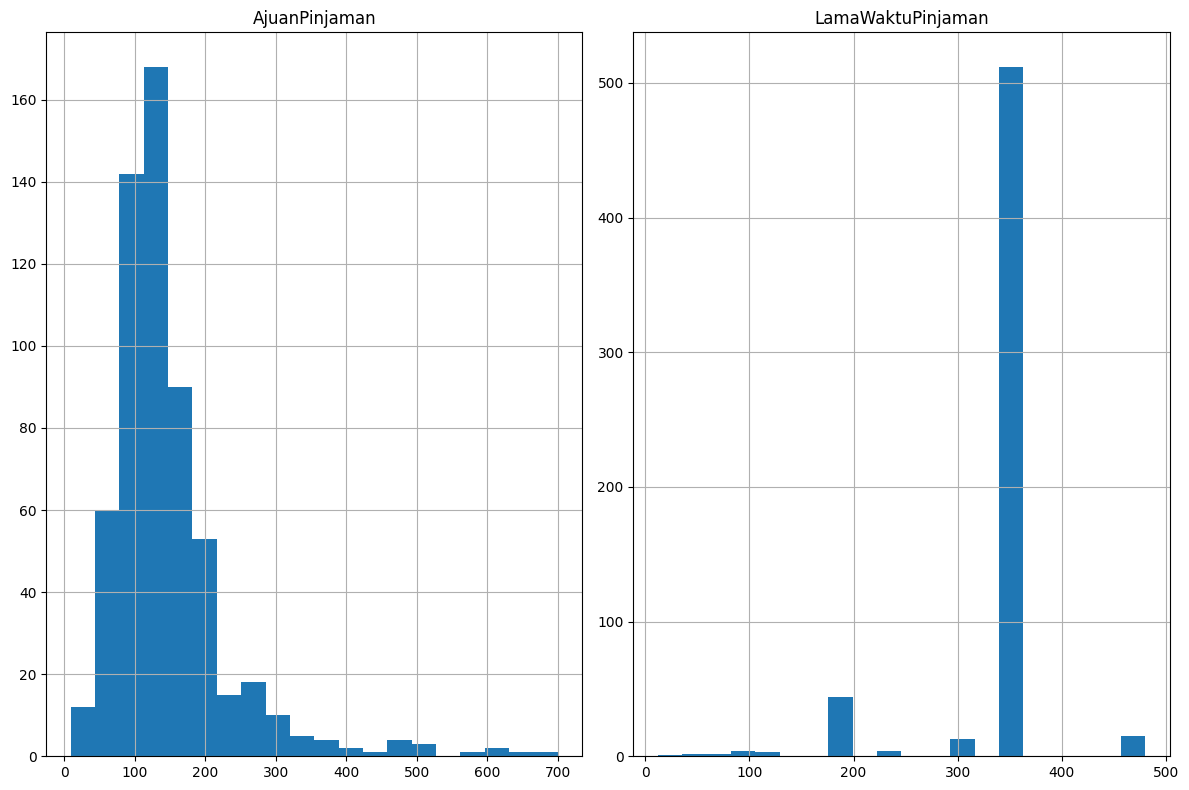

In [ ]:
# Histogram variabel numerik
df[['AjuanPinjaman',
    'LamaWaktuPinjaman']].hist(
    figsize=(12, 8),
    bins=20
)

plt.tight_layout()
plt.show()

#### Penanganan missing value

Berdasarkan hasil pemeriksaan missing value, terdapat missing value pada variabel JenisKelamin, StatusMenikah, Tanggungan, Wirausaha, AjuanPinjaman, LamaWaktuPinjaman, dan PernahPinjam. Penanganan missing value dilakukan dengan mempertimbangkan karakteristik dan distribusi masing-masing variabel. Variabel AjuanPinjaman memiliki distribusi yang menceng ke kanan sehingga missing value ditangani menggunakan median yang lebih robust terhadap pencilan. Variabel LamaWaktuPinjaman memiliki distribusi yang terkonsentrasi pada beberapa nilai tertentu sehingga digunakan modus sebagai nilai imputasi. Sementara itu, PernahPinjam merupakan variabel kategorik biner sehingga missing value ditangani menggunakan modus dari kategori yang paling dominan.

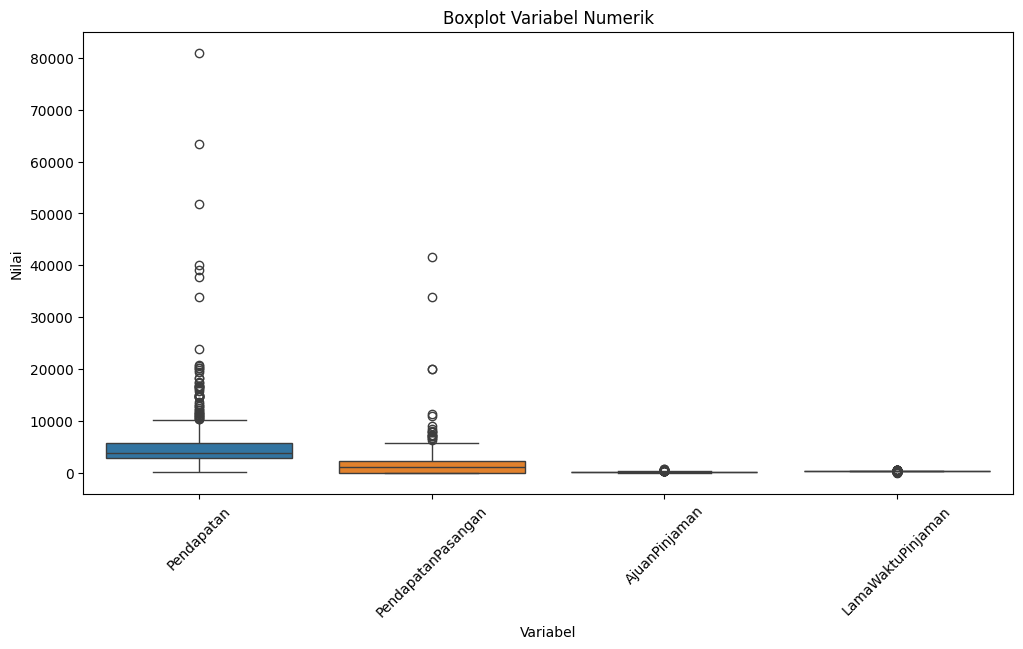

In [ ]:
# Boxplot untuk mendeteksi outlier pada variabel numerik

kolom_numerik = [
    'Pendapatan',
    'PendapatanPasangan',
    'AjuanPinjaman',
    'LamaWaktuPinjaman'
]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[kolom_numerik])

plt.title('Boxplot Variabel Numerik')
plt.xlabel('Variabel')
plt.ylabel('Nilai')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Imputasi variabel kategorik menggunakan modus
kolom_kategorik = [
    'JenisKelamin',
    'StatusMenikah',
    'Tanggungan',
    'Wirausaha',
    'PernahPinjam'
]

for kolom in kolom_kategorik:
    df[kolom] = df[kolom].fillna(df[kolom].mode()[0])

# Imputasi variabel numerik menggunakan median
kolom_numerik = [
    'AjuanPinjaman',
    'LamaWaktuPinjaman'
]

for kolom in kolom_numerik:
    df[kolom] = df[kolom].fillna(df[kolom].median())

In [ ]:
# Mengecek kembali missing value
df.isnull().sum()

,0
ID_Pinjaman,0
JenisKelamin,0
StatusMenikah,0
Tanggungan,0
Pendidikan,0
Wirausaha,0
Pendapatan,0
PendapatanPasangan,0
AjuanPinjaman,0
LamaWaktuPinjaman,0


## 6. Deteksi dan Penghapusan Data Duplikat

Pada tahap ini dilakukan pemeriksaan terhadap data duplikat. Apabila terdapat baris data yang memiliki informasi yang sama, salah satu data yang terduplikasi akan dihapus agar tidak memengaruhi hasil analisis.

In [ ]:
# Mengecek jumlah baris duplikat
jumlah_duplikat = df.duplicated().sum()

print("Jumlah data duplikat:", jumlah_duplikat)

Jumlah data duplikat: 0


In [ ]:
# Menampilkan baris yang terdeteksi sebagai duplikat
df[df.duplicated()]

,ID_Pinjaman,JenisKelamin,StatusMenikah,Tanggungan,Pendidikan,Wirausaha,Pendapatan,PendapatanPasangan,AjuanPinjaman,LamaWaktuPinjaman,PernahPinjam,LokasiRumah,StatusPinjaman


## 7. Deteksi dan Penanganan Pencilan

Pada tahap ini dilakukan pemeriksaan awal terhadap kemungkinan adanya pencilan pada variabel numerik menggunakan analisis deskriptif dan visualisasi. Apabila ditemukan pencilan, dilakukan penanganan yang sesuai berdasarkan karakteristik data.

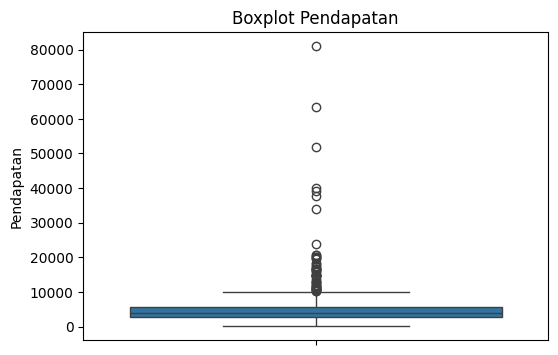

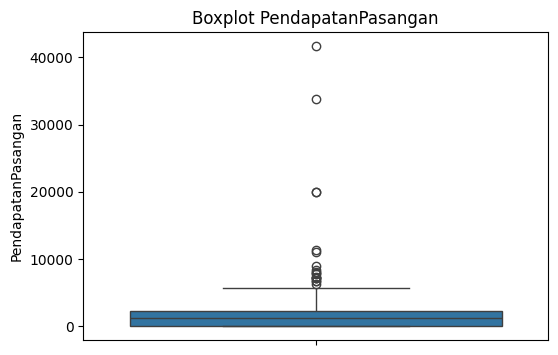

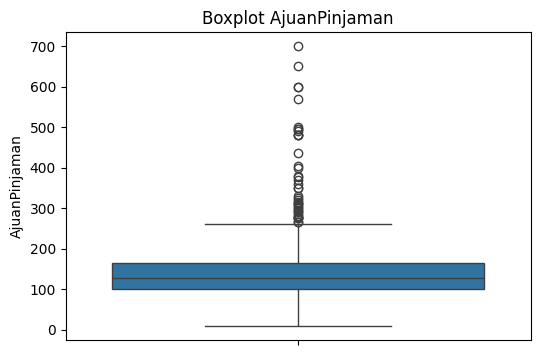

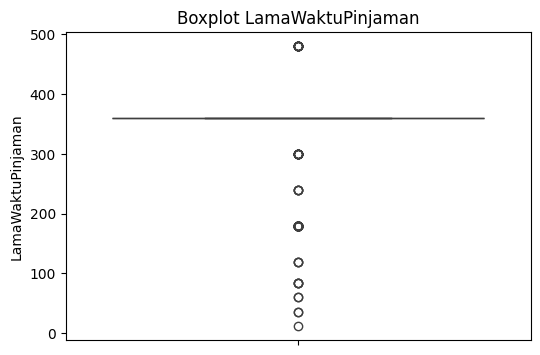

In [ ]:
kolom_numerik = [
    'Pendapatan',
    'PendapatanPasangan',
    'AjuanPinjaman',
    'LamaWaktuPinjaman'
]

for kolom in kolom_numerik:
    plt.figure(figsize=(6, 4))
    sns.boxplot(y=df[kolom])
    plt.title(f'Boxplot {kolom}')
    plt.ylabel(kolom)
    plt.show()

In [ ]:
# Deteksi pencilan menggunakan metode IQR

kolom_numerik = [
    'Pendapatan',
    'PendapatanPasangan',
    'AjuanPinjaman',
    'LamaWaktuPinjaman'
]

hasil_outlier = []

for kolom in kolom_numerik:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    ).sum()

    hasil_outlier.append({
        'Variabel': kolom,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Batas Bawah': batas_bawah,
        'Batas Atas': batas_atas,
        'Jumlah Outlier': jumlah_outlier
    })

hasil_outlier = pd.DataFrame(hasil_outlier)

hasil_outlier

,Variabel,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier
0,Pendapatan,2877.50,5795.00,2917.50,-1498.750,10171.250,50
1,PendapatanPasangan,0.00,2297.25,2297.25,-3445.875,5743.125,18
2,AjuanPinjaman,100.25,164.75,64.50,3.500,261.500,41
3,LamaWaktuPinjaman,360.00,360.00,0.00,360.000,360.000,88


In [ ]:
# Penanganan pencilan dengan metode Capping (IQR)

kolom_numerik = [
    'Pendapatan',
    'PendapatanPasangan',
    'AjuanPinjaman'
]

for kolom in kolom_numerik:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    # Capping nilai yang berada di luar batas
    df[kolom] = df[kolom].clip(
        lower=batas_bawah,
        upper=batas_atas
    )

In [ ]:
# Mengecek kembali pencilan setelah capping

for kolom in kolom_numerik:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    ).sum()

    print(f'{kolom}: {jumlah_outlier} outlier')

Pendapatan: 0 outlier
PendapatanPasangan: 0 outlier
AjuanPinjaman: 0 outlier


Berdasarkan hasil deteksi menggunakan metode IQR, ditemukan beberapa observasi yang berada di luar batas pencilan pada variabel numerik. Nilai tersebut tidak langsung dianggap sebagai kesalahan karena variabel pendapatan dan jumlah pinjaman secara alami dapat memiliki nilai yang tinggi antar nasabah. Oleh karena itu, pencilan tidak dihapus karena dapat menyebabkan hilangnya informasi dan mengurangi jumlah observasi. Penanganan dilakukan menggunakan metode capping untuk membatasi nilai ekstrem pada batas IQR sehingga pengaruh pencilan terhadap pemodelan dapat dikurangi, sementara jumlah observasi tetap dipertahankan.

In [ ]:
df

,ID_Pinjaman,JenisKelamin,StatusMenikah,Tanggungan,Pendidikan,Wirausaha,Pendapatan,PendapatanPasangan,AjuanPinjaman,LamaWaktuPinjaman,PernahPinjam,LokasiRumah,StatusPinjaman
0,LP001002,Male,No,0,Graduate,No,5849.0,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583.0,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000.0,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583.0,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000.0,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900.0,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106.0,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072.0,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583.0,0.0,187.0,360.0,1.0,Urban,Y


## 8. Encoding Variabel Kategorik

Variabel kategorik yang memiliki nilai berupa teks akan diubah ke dalam bentuk numerik melalui proses encoding agar dapat digunakan dalam proses pemodelan machine learning.

In [ ]:
kolom_kategorik = [
    'JenisKelamin',
    'StatusMenikah',
    'Tanggungan',
    'Pendidikan',
    'Wirausaha',
    'PernahPinjam',
    'LokasiRumah',
    'StatusPinjaman'
]

In [ ]:
print(kolom_kategorik)

['JenisKelamin', 'StatusMenikah', 'Tanggungan', 'Pendidikan', 'Wirausaha', 'PernahPinjam', 'LokasiRumah', 'StatusPinjaman']


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for kolom in kolom_kategorik:
    # Fit encoder
    le.fit(df[kolom].astype(str))

    # Tampilkan mapping
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))

    print(f"\nMapping {kolom}:")
    for kategori, kode in mapping.items():
        print(f"  {kategori} -> {kode}")

    # Encoding data
    df[kolom] = le.transform(df[kolom].astype(str))


Mapping JenisKelamin:
  Female -> 0
  Male -> 1

Mapping StatusMenikah:
  No -> 0
  Yes -> 1

Mapping Tanggungan:
  0 -> 0
  1 -> 1
  2 -> 2
  3+ -> 3

Mapping Pendidikan:
  Graduate -> 0
  Not Graduate -> 1

Mapping Wirausaha:
  No -> 0
  Yes -> 1

Mapping PernahPinjam:
  0.0 -> 0
  1.0 -> 1

Mapping LokasiRumah:
  Rural -> 0
  Semiurban -> 1
  Urban -> 2

Mapping StatusPinjaman:
  N -> 0
  Y -> 1


In [ ]:
df

,ID_Pinjaman,JenisKelamin,StatusMenikah,Tanggungan,Pendidikan,Wirausaha,Pendapatan,PendapatanPasangan,AjuanPinjaman,LamaWaktuPinjaman,PernahPinjam,LokasiRumah,StatusPinjaman
0,LP001002,1,0,0,0,0,5849.0,0.0,128.0,360.0,1,2,1
1,LP001003,1,1,1,0,0,4583.0,1508.0,128.0,360.0,1,0,0
2,LP001005,1,1,0,0,1,3000.0,0.0,66.0,360.0,1,2,1
3,LP001006,1,1,0,1,0,2583.0,2358.0,120.0,360.0,1,2,1
4,LP001008,1,0,0,0,0,6000.0,0.0,141.0,360.0,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,0,0,0,0,0,2900.0,0.0,71.0,360.0,1,0,1
610,LP002979,1,1,3,0,0,4106.0,0.0,40.0,180.0,1,0,1
611,LP002983,1,1,1,0,0,8072.0,240.0,253.0,360.0,1,2,1
612,LP002984,1,1,2,0,0,7583.0,0.0,187.0,360.0,1,2,1


In [ ]:
for kolom in kolom_kategorik:
    print(f"\nCount {kolom}:")
    print(df[kolom].value_counts().sort_index())


Count JenisKelamin:
JenisKelamin
0    112
1    502
Name: count, dtype: int64

Count StatusMenikah:
StatusMenikah
0    213
1    401
Name: count, dtype: int64

Count Tanggungan:
Tanggungan
0    360
1    102
2    101
3     51
Name: count, dtype: int64

Count Pendidikan:
Pendidikan
0    480
1    134
Name: count, dtype: int64

Count Wirausaha:
Wirausaha
0    532
1     82
Name: count, dtype: int64

Count PernahPinjam:
PernahPinjam
0     89
1    525
Name: count, dtype: int64

Count LokasiRumah:
LokasiRumah
0    179
1    233
2    202
Name: count, dtype: int64

Count StatusPinjaman:
StatusPinjaman
0    192
1    422
Name: count, dtype: int64


## 9. Data Bersih

Hasil dari proses pemeriksaan dan penanganan missing value, data duplikat, pencilan, serta proses encoding pada tahap sebelumnya digunakan sebagai DATA BERSIH yang selanjutnya digunakan untuk analisis dan pemodelan.

In [ ]:
# Membuat salinan data setelah seluruh proses preprocessing

df_bersih = df.copy()  # Menyimpan hasil tahapan 5 sampai 8 sebagai DATA BERSIH

print("Ukuran DATA BERSIH:", df_bersih.shape)  # Menampilkan jumlah baris dan kolom
display(df_bersih.head())  # Menampilkan 5 baris pertama DATA BERSIH

Ukuran DATA BERSIH: (614, 13)


,ID_Pinjaman,JenisKelamin,StatusMenikah,Tanggungan,Pendidikan,Wirausaha,Pendapatan,PendapatanPasangan,AjuanPinjaman,LamaWaktuPinjaman,PernahPinjam,LokasiRumah,StatusPinjaman
0,LP001002,1,0,0,0,0,5849.0,0.0,128.0,360.0,1,2,1
1,LP001003,1,1,1,0,0,4583.0,1508.0,128.0,360.0,1,0,0
2,LP001005,1,1,0,0,1,3000.0,0.0,66.0,360.0,1,2,1
3,LP001006,1,1,0,1,0,2583.0,2358.0,120.0,360.0,1,2,1
4,LP001008,1,0,0,0,0,6000.0,0.0,141.0,360.0,1,2,1


## 10. Analisis Statistika Deskriptif

Pada tahap ini dilakukan analisis statistika deskriptif secara numerik dan grafik terhadap setiap variabel pada DATA BERSIH. Analisis disesuaikan dengan tipe dan skala pengukuran masing-masing variabel.

In [ ]:
# Variabel kategorik
kolom_kategorik = [
    'JenisKelamin',
    'StatusMenikah',
    'Tanggungan',
    'Pendidikan',
    'Wirausaha',
    'PernahPinjam',
    'LokasiRumah',
    'StatusPinjaman'
]

for kolom in kolom_kategorik:
    print(f'\n=== {kolom} ===')

    frekuensi = df_bersih[kolom].value_counts().sort_index()
    persentase = df_bersih[kolom].value_counts(
        normalize=True
    ).sort_index() * 100

    hasil = pd.DataFrame({
        'Frekuensi': frekuensi,
        'Persentase (%)': persentase.round(2)
    })

    print(hasil)


=== JenisKelamin ===
              Frekuensi  Persentase (%)
JenisKelamin                           
0                   112           18.24
1                   502           81.76

=== StatusMenikah ===
               Frekuensi  Persentase (%)
StatusMenikah                           
0                    213           34.69
1                    401           65.31

=== Tanggungan ===
            Frekuensi  Persentase (%)
Tanggungan                           
0                 360           58.63
1                 102           16.61
2                 101           16.45
3                  51            8.31

=== Pendidikan ===
            Frekuensi  Persentase (%)
Pendidikan                           
0                 480           78.18
1                 134           21.82

=== Wirausaha ===
           Frekuensi  Persentase (%)
Wirausaha                           
0                532           86.64
1                 82           13.36

=== PernahPinjam ===
              Frekuens

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for kolom in kolom_kategorik:
    plt.figure(figsize=(6, 4))

    ax = sns.countplot(
        x=df_bersih[kolom]
    )

    # Menampilkan angka frekuensi di atas batang
    for container in ax.containers:
        ax.bar_label(container, padding=3)

    plt.title(f'Distribusi {kolom}')
    plt.xlabel(kolom)
    plt.ylabel('Frekuensi')
    plt.tight_layout()
    plt.show()

In [ ]:
kolom_numerik = [
    'Pendapatan',
    'PendapatanPasangan',
    'AjuanPinjaman',
    'LamaWaktuPinjaman'
]

In [ ]:
df_bersih[kolom_numerik].describe()

In [ ]:
# Boxplot variabel numerik

for kolom in kolom_numerik:
    plt.figure(figsize=(6, 4))

    sns.boxplot(y=df_bersih[kolom])

    plt.title(f'Boxplot {kolom}')
    plt.ylabel(kolom)
    plt.tight_layout()
    plt.show()

In [ ]:
plt.figure(figsize=(7, 4))

sns.histplot(df_bersih['LamaWaktuPinjaman'], discrete=True)

plt.title('Distribusi LamaWaktuPinjaman')
plt.xlabel('Lama Waktu Pinjaman')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

## 11. Analisis Variabel Independen Kategorik

Untuk setiap variabel independen bertipe kategorik, dibuat tabel kontingensi dengan variabel dependen StatusPinjaman. Tabel tersebut digunakan untuk melihat distribusi status pinjaman pada masing-masing kategori variabel independen serta mengidentifikasi hubungan antara keduanya.

In [ ]:
kolom_kategorik = [
    'JenisKelamin',
    'StatusMenikah',
    'Tanggungan',
    'Pendidikan',
    'Wirausaha',
    'PernahPinjam',
    'LokasiRumah'
]

In [ ]:
# Tabel kontingensi variabel independen kategorik dengan StatusPinjaman

for kolom in kolom_kategorik:
    print(f'\n=== Tabel Kontingensi {kolom} dengan StatusPinjaman ===')

    tabel_kontingensi = pd.crosstab(
        df_bersih[kolom],
        df_bersih['StatusPinjaman']
    )

    print(tabel_kontingensi)

In [ ]:
for kolom in kolom_kategorik:
    print(f'\n=== {kolom} vs StatusPinjaman ===')

    tabel = pd.crosstab(
        df_bersih[kolom],
        df_bersih['StatusPinjaman']
    )

    print('Frekuensi:')
    print(tabel)

    print('\nPersentase per kategori:')
    print(
        pd.crosstab(
            df_bersih[kolom],
            df_bersih['StatusPinjaman'],
            normalize='index'
        ).mul(100).round(2)
    )

In [ ]:
from scipy.stats import chi2_contingency

In [ ]:
for kolom in kolom_kategorik:
    tabel = pd.crosstab(
        df_bersih[kolom],
        df_bersih['StatusPinjaman']
    )

    chi2, p_value, dfree, expected = chi2_contingency(tabel)

    print(f'\n=== Uji Chi-Square: {kolom} vs StatusPinjaman ===')
    print(f'Chi-Square : {chi2:.4f}')
    print(f'p-value    : {p_value:.4f}')

In [ ]:
alpha = 0.05

for kolom in kolom_kategorik:
    tabel = pd.crosstab(
        df_bersih[kolom],
        df_bersih['StatusPinjaman']
    )

    chi2, p_value, dfree, expected = chi2_contingency(tabel)

    if p_value < alpha:
        kesimpulan = 'Terdapat hubungan'
    else:
        kesimpulan = 'Tidak terdapat hubungan'

    print(f'{kolom}: p-value = {p_value:.4f} → {kesimpulan}')

In [ ]:
from scipy.stats import chi2_contingency

for kolom in kolom_kategorik:
    tabel = pd.crosstab(
        df_bersih[kolom],
        df_bersih['StatusPinjaman']
    )

    chi2, p_value, dfree, expected = chi2_contingency(tabel)

    n = tabel.to_numpy().sum()
    r, k = tabel.shape

    cramer_v = (chi2 / (n * min(r - 1, k - 1))) ** 0.5

    print(f'\n=== {kolom} vs StatusPinjaman ===')
    print(f'Chi-Square : {chi2:.4f}')
    print(f'p-value    : {p_value:.4f}')
    print(f"Cramer's V : {cramer_v:.4f}")

In [ ]:
hasil_cramer = []

for kolom in kolom_kategorik:
    tabel = pd.crosstab(df_bersih[kolom], df_bersih['StatusPinjaman'])

    chi2, p_value, dfree, expected = chi2_contingency(tabel)

    n = tabel.to_numpy().sum()
    r, k = tabel.shape

    cramer_v = (chi2 / (n * min(r - 1, k - 1))) ** 0.5

    hasil_cramer.append({
        'Variabel': kolom,
        "Cramer's V": cramer_v,
        'p-value': p_value
    })

hasil_cramer = pd.DataFrame(hasil_cramer)

hasil_cramer

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=hasil_cramer,
    x="Cramer's V",
    y='Variabel'
)

# Menampilkan nilai Cramer's V
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)

plt.title("Kekuatan Hubungan Variabel Kategorik dengan StatusPinjaman")
plt.xlabel("Cramer's V")
plt.ylabel("Variabel")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

hasil_cramer = []

for kolom in kolom_kategorik:
    tabel = pd.crosstab(
        df_bersih[kolom],
        df_bersih['StatusPinjaman']
    )

    chi2, p_value, dfree, expected = chi2_contingency(tabel)

    n = tabel.to_numpy().sum()
    r, k = tabel.shape

    cramer_v = np.sqrt(
        chi2 / (n * min(r - 1, k - 1))
    )

    hasil_cramer.append({
        'Variabel': kolom,
        "Cramer's V": cramer_v
    })

hasil_cramer = pd.DataFrame(hasil_cramer)

In [ ]:
heatmap_data = hasil_cramer.set_index('Variabel')

plt.figure(figsize=(6, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.3f',
    cmap='Blues',
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title("Cramer's V Variabel Kategorik terhadap StatusPinjaman")
plt.xlabel('')
plt.ylabel('Variabel')
plt.tight_layout()
plt.show()

## 12. Analisis Variabel Independen Numerik

Untuk setiap variabel independen bertipe numerik, dibuat diagram pencar dengan variabel independen pada sumbu horizontal dan StatusPinjaman pada sumbu vertikal. Visualisasi tersebut digunakan untuk mengamati pola hubungan antara variabel numerik dengan status pinjaman.

In [ ]:
kolom_numerik = [
    'Pendapatan',
    'PendapatanPasangan',
    'AjuanPinjaman',
    'LamaWaktuPinjaman'
]

In [ ]:
for kolom in kolom_numerik:
    print(f'\n=== {kolom} berdasarkan StatusPinjaman ===')

    print(
        df_bersih.groupby('StatusPinjaman')[kolom].describe().round(2)
    )

In [ ]:
# Variabel independen numerik
kolom_numerik = [
    'Pendapatan',
    'PendapatanPasangan',
    'AjuanPinjaman',
    'LamaWaktuPinjaman'
]

# Scatter plot X numerik terhadap Y
for kolom in kolom_numerik:
    plt.figure(figsize=(7, 4))

    sns.scatterplot(
        data=df_bersih,
        x=kolom,
        y='StatusPinjaman'
    )

    plt.title(f'Hubungan {kolom} dengan StatusPinjaman')
    plt.xlabel(kolom)
    plt.ylabel('StatusPinjaman')
    plt.tight_layout()
    plt.show()

In [ ]:
from scipy.stats import pointbiserialr

hasil_korelasi = []

for kolom in kolom_numerik:
    r, p = pointbiserialr(
        df_bersih['StatusPinjaman'],
        df_bersih[kolom]
    )

    hasil_korelasi.append({
        'Variabel': kolom,
        'Korelasi': r,
        'p-value': p
    })

hasil_korelasi = pd.DataFrame(hasil_korelasi)

hasil_korelasi

In [ ]:
for kolom in kolom_numerik:
    print(kolom)
    print('Jumlah nilai unik:', df_bersih[kolom].nunique())
    print('Nilai unik:', df_bersih[kolom].unique()) erorrrmclll

In [ ]:
df_bersih.dtypes

## 13. Pembagian Data Training dan Testing

Dataset dibagi menjadi data training dan data testing dengan perbandingan 80:20. Data training digunakan untuk membangun model, sedangkan data testing digunakan untuk mengevaluasi performa model pada data yang belum digunakan dalam proses pelatihan.

In [ ]:
X = df_bersih.drop(columns=['StatusPinjaman', 'ID_Pinjaman'])
y = df_bersih['StatusPinjaman']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Decision Tree terbaik

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

dt = DecisionTreeClassifier(random_state=42)

param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

grid_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid_dt,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_dt.fit(X_train, y_train)

print("Parameter terbaik:", grid_dt.best_params_)
print("CV score terbaik:", grid_dt.best_score_)

Parameter terbaik: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}
CV score terbaik: 0.8621115372838133


In [ ]:
best_dt = grid_dt.best_estimator_

## REGLOG Terbaik

In [ ]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(
    max_iter=10000,
    random_state=42
)

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs']
}

grid_lr = GridSearchCV(
    estimator=logreg,
    param_grid=param_grid_lr,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

print("Parameter terbaik:", grid_lr.best_params_)
print("CV score terbaik:", grid_lr.best_score_)

Parameter terbaik: {'C': 0.1, 'solver': 'lbfgs'}
CV score terbaik: 0.8699456484348126


In [ ]:
best_lr = grid_lr.best_estimator_

## bandingin

In [ ]:
print("Decision Tree CV F1 :", grid_dt.best_score_)
print("Logistic Regression CV F1 :", grid_lr.best_score_)

Decision Tree CV F1 : 0.8621115372838133
Logistic Regression CV F1 : 0.8699456484348126


In [ ]:
intercept = best_lr.intercept_[0]
koef = best_lr.coef_[0]

persamaan = f"logit(p) = {intercept:.4f}"

for nama, beta in zip(X_train.columns, koef):
    tanda = "+" if beta >= 0 else "-"
    persamaan += f" {tanda} {abs(beta):.4f}({nama})"

print(persamaan)

logit(p) = -0.7912 - 0.0842(JenisKelamin) + 0.2758(StatusMenikah) + 0.0763(Tanggungan) - 0.2659(Pendidikan) - 0.0541(Wirausaha) + 0.0000(Pendapatan) + 0.0000(PendapatanPasangan) - 0.0022(AjuanPinjaman) + 0.0007(LamaWaktuPinjaman) + 1.7058(PernahPinjam) + 0.0603(LokasiRumah)


In [ ]:
intercept = best_lr.intercept_[0]
koef = best_lr.coef_[0]

print(intercept)
print(koef)

-0.7911839265123026
[-8.41893024e-02  2.75814645e-01  7.63466650e-02 -2.65947885e-01
 -5.40664359e-02  2.49529594e-06  2.17879837e-05 -2.22262668e-03
  7.14286315e-04  1.70578211e+00  6.03362491e-02]


In [ ]:
from sklearn.tree import export_text

rules = export_text(
    best_dt,
    feature_names=list(X_train.columns)
)

print(rules)

|--- PernahPinjam <= 0.50
|   |--- AjuanPinjaman <= 136.50
|   |   |--- LamaWaktuPinjaman <= 240.00
|   |   |   |--- class: 0
|   |   |--- LamaWaktuPinjaman >  240.00
|   |   |   |--- class: 0
|   |--- AjuanPinjaman >  136.50
|   |   |--- LokasiRumah <= 0.50
|   |   |   |--- class: 0
|   |   |--- LokasiRumah >  0.50
|   |   |   |--- class: 0
|--- PernahPinjam >  0.50
|   |--- AjuanPinjaman <= 166.00
|   |   |--- PendapatanPasangan <= 745.00
|   |   |   |--- class: 1
|   |   |--- PendapatanPasangan >  745.00
|   |   |   |--- class: 1
|   |--- AjuanPinjaman >  166.00
|   |   |--- PendapatanPasangan <= 1534.00
|   |   |   |--- class: 1
|   |   |--- PendapatanPasangan >  1534.00
|   |   |   |--- class: 1



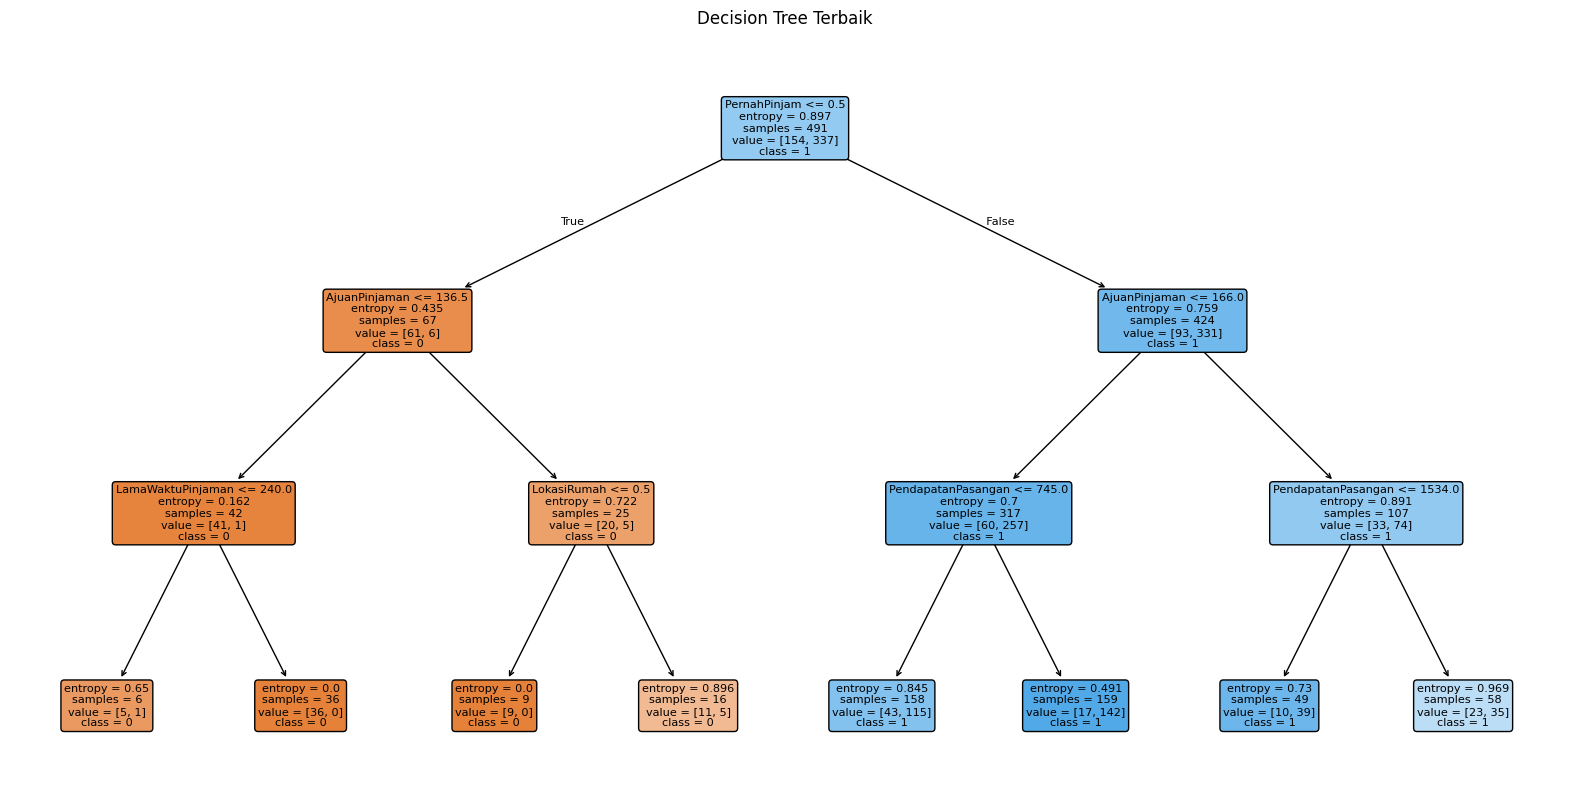

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    best_dt,
    feature_names=X_train.columns,
    class_names=['0', '1'],
    filled=True,
    rounded=True
)

plt.title("Decision Tree Terbaik")
plt.show()

## test set

In [ ]:
y_pred = best_lr.predict(X_test)
y_prob = best_lr.predict_proba(X_test)[:, 1]

In [ ]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))
print("AUC      :", roc_auc_score(y_test, y_prob))

Accuracy : 0.8536585365853658
Precision: 0.8316831683168316
Recall   : 0.9882352941176471
F1-score : 0.9032258064516129
AUC      : 0.8278637770897833


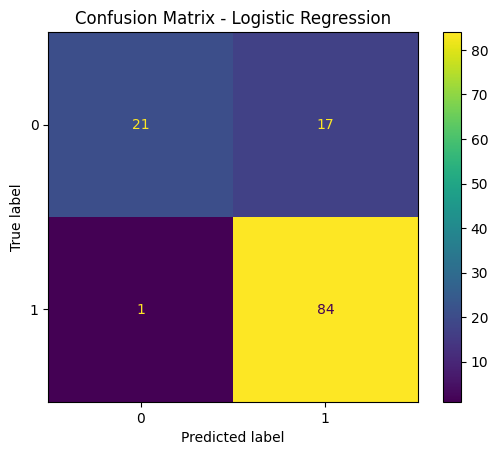

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Prediksi data testing
y_pred_lr = best_lr.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['0', '1']
)

disp.plot()
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

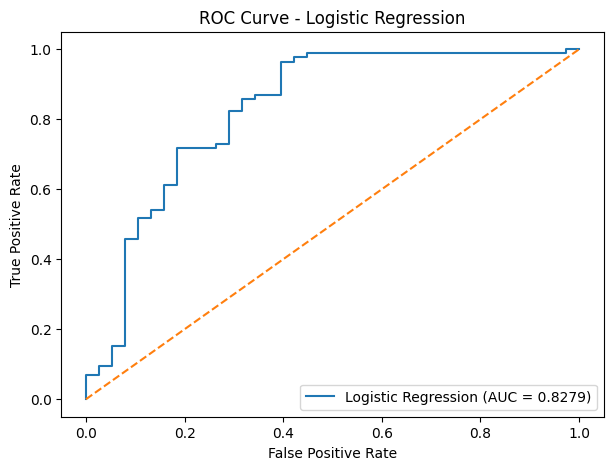

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Probabilitas kelas 1
y_prob_lr = best_lr.predict_proba(X_test)[:, 1]

# ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_lr)

# AUC
auc_lr = roc_auc_score(y_test, y_prob_lr)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {auc_lr:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    'Decision Tree': best_dt,
    'Logistic Regression': best_lr
}

for nama, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"\n{nama}")
    print("Accuracy :", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall   :", recall_score(y_test, y_pred))
    print("F1-score :", f1_score(y_test, y_pred))
    print("AUC      :", roc_auc_score(y_test, y_prob))


Decision Tree
Accuracy : 0.8536585365853658
Precision: 0.8316831683168316
Recall   : 0.9882352941176471
F1-score : 0.9032258064516129
AUC      : 0.7730650154798762

Logistic Regression
Accuracy : 0.8536585365853658
Precision: 0.8316831683168316
Recall   : 0.9882352941176471
F1-score : 0.9032258064516129
AUC      : 0.8278637770897833


In [ ]:
hasil_model = []

for nama, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    hasil_model.append({
        'Model': nama,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_prob)
    })

hasil_df = pd.DataFrame(hasil_model)

print(hasil_df)

                 Model  Accuracy  Precision    Recall  F1-score       AUC
0        Decision Tree  0.853659   0.831683  0.988235  0.903226  0.773065
1  Logistic Regression  0.853659   0.831683  0.988235  0.903226  0.827864


In [ ]:
y_pred_dt = best_dt.predict(X_test)
y_pred_lr = best_lr.predict(X_test)

print("Jumlah prediksi berbeda:",
      (y_pred_dt != y_pred_lr).sum())

print("Semua prediksi sama?",
      (y_pred_dt == y_pred_lr).all())

Jumlah prediksi berbeda: 0
Semua prediksi sama? True


In [ ]:
print("=== DECISION TREE ===")
print("Best Parameters:")
print(grid_dt.best_params_)

print("\nModel:")
print(best_dt)


print("\n=== LOGISTIC REGRESSION ===")
print("Best Parameters:")
print(grid_lr.best_params_)

print("\nModel:")
print(best_lr)

=== DECISION TREE ===
Best Parameters:
{'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}

Model:
DecisionTreeClassifier(criterion='entropy', max_depth=3, min_samples_leaf=5,
                       random_state=42)

=== LOGISTIC REGRESSION ===
Best Parameters:
{'C': 0.1, 'solver': 'lbfgs'}

Model:
LogisticRegression(C=0.1, max_iter=10000, random_state=42)


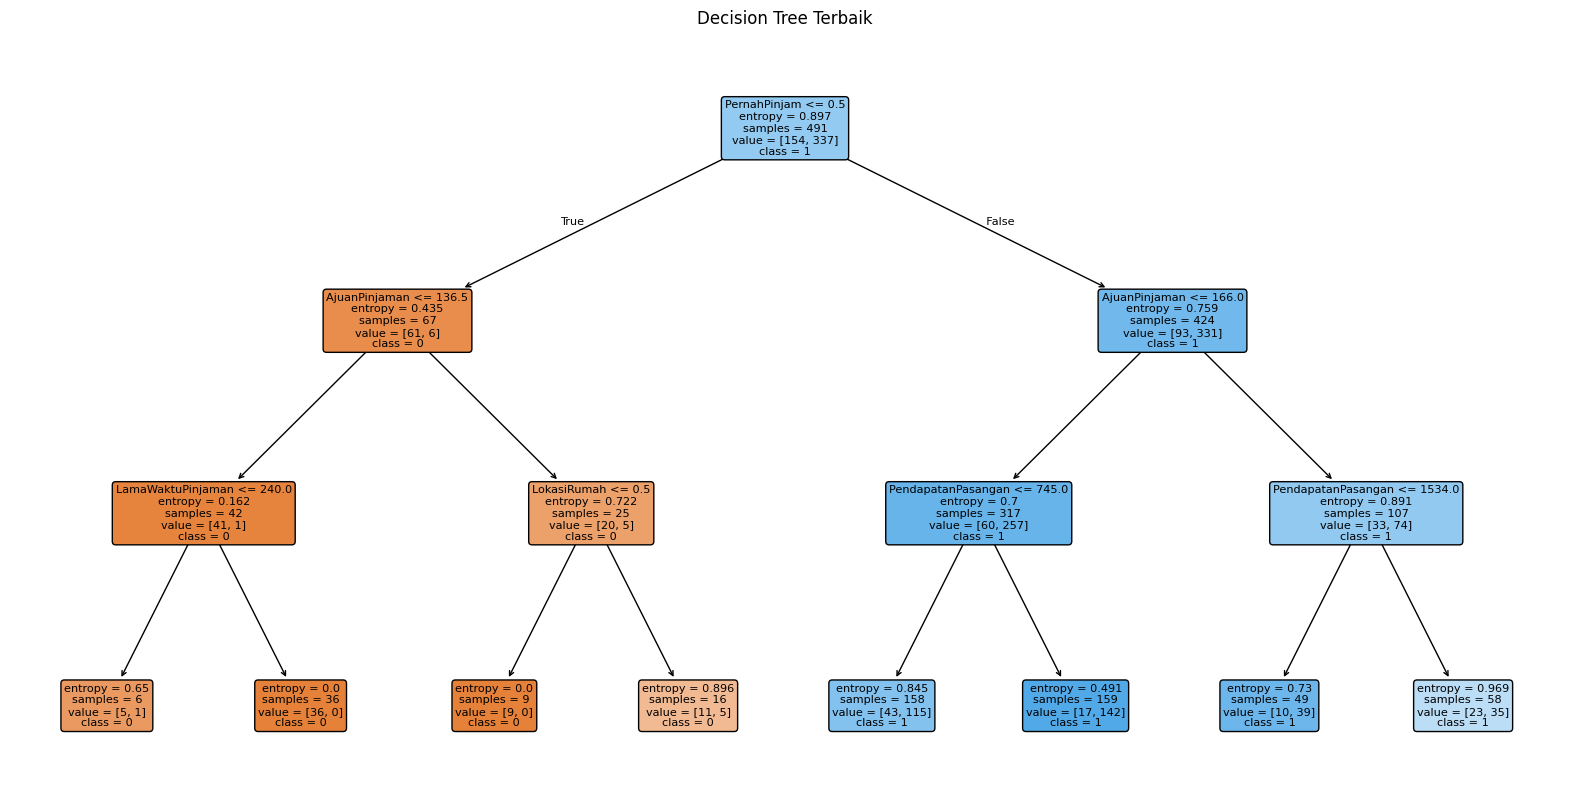

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    best_dt,
    feature_names=X_train.columns,
    class_names=['0', '1'],
    filled=True,
    rounded=True
)

plt.title("Decision Tree Terbaik")
plt.show()

In [ ]:
coef_lr = pd.DataFrame({
    'Variabel': X_train.columns,
    'Koefisien': best_lr.coef_[0]
})

print(coef_lr)

              Variabel  Koefisien
0         JenisKelamin  -0.084189
1        StatusMenikah   0.275815
2           Tanggungan   0.076347
3           Pendidikan  -0.265948
4            Wirausaha  -0.054066
5           Pendapatan   0.000002
6   PendapatanPasangan   0.000022
7        AjuanPinjaman  -0.002223
8    LamaWaktuPinjaman   0.000714
9         PernahPinjam   1.705782
10         LokasiRumah   0.060336


In [ ]:
import numpy as np

coef_lr['Odds Ratio'] = np.exp(coef_lr['Koefisien'])

print(coef_lr)

              Variabel  Koefisien  Odds Ratio
0         JenisKelamin  -0.084189    0.919257
1        StatusMenikah   0.275815    1.317604
2           Tanggungan   0.076347    1.079337
3           Pendidikan  -0.265948    0.766479
4            Wirausaha  -0.054066    0.947369
5           Pendapatan   0.000002    1.000002
6   PendapatanPasangan   0.000022    1.000022
7        AjuanPinjaman  -0.002223    0.997780
8    LamaWaktuPinjaman   0.000714    1.000715
9         PernahPinjam   1.705782    5.505690
10         LokasiRumah   0.060336    1.062194


In [ ]:
import pandas as pd
import numpy as np

coef_lr = pd.DataFrame({
    'Variabel': X_train.columns,
    'Koefisien': best_lr.coef_[0]
})

coef_lr['Odds Ratio'] = np.exp(coef_lr['Koefisien'])

print("Intercept:", best_lr.intercept_[0])
print("\nKoefisien dan Odds Ratio:")
print(coef_lr)

Intercept: -0.7911839265123026

Koefisien dan Odds Ratio:
              Variabel  Koefisien  Odds Ratio
0         JenisKelamin  -0.084189    0.919257
1        StatusMenikah   0.275815    1.317604
2           Tanggungan   0.076347    1.079337
3           Pendidikan  -0.265948    0.766479
4            Wirausaha  -0.054066    0.947369
5           Pendapatan   0.000002    1.000002
6   PendapatanPasangan   0.000022    1.000022
7        AjuanPinjaman  -0.002223    0.997780
8    LamaWaktuPinjaman   0.000714    1.000715
9         PernahPinjam   1.705782    5.505690
10         LokasiRumah   0.060336    1.062194


In [ ]:
# ============================================================
# 13. PEMBAGIAN DATA TRAIN DAN DATA TEST
# ============================================================

from sklearn.model_selection import train_test_split  # Memanggil fungsi pembagian data

target = 'StatusPinjaman'  # Menentukan variabel dependen

X = df_bersih.drop(columns=[target])  # Menentukan variabel independen

y = df_bersih[target]  # Menentukan variabel dependen

X_train, X_test, y_train, y_test = train_test_split(  # Membagi data menjadi train dan test
    X,
    y,
    test_size=0.20,  # Menentukan 20% data sebagai data testing
    train_size=0.80,  # Menentukan 80% data sebagai data training
    random_state=42  # Menetapkan seed agar hasil pembagian konsisten
)

print("Jumlah data keseluruhan :", len(df_bersih))  # Menampilkan jumlah seluruh data
print("Jumlah data training   :", len(X_train))  # Menampilkan jumlah data training
print("Jumlah data testing    :", len(X_test))  # Menampilkan jumlah data testing

In [ ]:
print(X_train.dtypes)

In [ ]:
from sklearn.model_selection import train_test_split  # Memanggil fungsi pembagian data

target = 'StatusPinjaman'  # Menentukan variabel dependen

X = df_bersih.drop(columns=[target])  # Menentukan variabel independen

y = df_bersih[target]  # Menentukan variabel dependen

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,       # Menentukan 20% data sebagai data testing
    train_size=0.80,      # Menentukan 80% data sebagai data training
    random_state=42,      # Menetapkan seed agar hasil pembagian konsisten
    stratify=y            # Mempertahankan proporsi kelas StatusPinjaman
)

print("Jumlah data keseluruhan :", len(df_bersih))
print("Jumlah data training    :", len(X_train))
print("Jumlah data testing     :", len(X_test))

In [ ]:
print("Jumlah data keseluruhan :", len(df_bersih))  # Menampilkan jumlah seluruh data
print("Jumlah data training   :", len(X_train))  # Menampilkan jumlah data training
print("Jumlah data testing    :", len(X_test))  # Menampilkan jumlah data testing

## 14. Pemeriksaan Keseimbangan Variabel Dependen

Pada data training dilakukan pemeriksaan terhadap proporsi masing-masing kategori StatusPinjaman. Apabila terdapat ketidakseimbangan kelas, dilakukan penanganan yang sesuai agar model tidak terlalu dominan dalam memprediksi kelas mayoritas.

In [ ]:
print("Proporsi StatusPinjaman pada data training:")
print(y_train.value_counts(normalize=True))

print("\nProporsi StatusPinjaman pada data testing:")
print(y_test.value_counts(normalize=True))

## 15. Pemodelan dan Pemilihan Model Terbaik

Pada tahap ini dibangun beberapa model klasifikasi menggunakan data training untuk mengetahui hubungan antara StatusPinjaman dengan variabel-variabel independennya. Model yang digunakan sebagai kandidat antara lain Logistic Regression, Decision Tree, dan Random Forest. Selanjutnya, performa masing-masing model dibandingkan untuk menentukan model terbaik.

In [ ]:
print(X_train.dtypes)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

cart = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)

cart.fit(X_train, y_train)

## 16. Evaluasi Performa Model Terbaik

Model terbaik yang telah dipilih kemudian diterapkan pada data testing untuk memperoleh evaluasi akhir. Evaluasi dilakukan menggunakan metrik accuracy, precision, recall, F1-score, AUC, serta kurva ROC untuk mengetahui kemampuan model dalam melakukan klasifikasi status kelayakan pinjaman.